# Basemaps for matplotlib from MapLibre styles

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kanahiro/ml2drender/blob/main/examples/python/basemap.ipynb)

`ml2drender.basemap` draws a [MapLibre style](https://maplibre.org/maplibre-style-spec/) under data plotted with matplotlib or GeoPandas, with the parameters of [contextily](https://contextily.readthedocs.io/)'s `add_basemap`. The style (vector tiles, labels, icons) is rendered once for the extent of the axes, at their resolution and directly in their CRS: no GPU, no browser, no raster tiles to merge or warp.

As contextily is `import contextily as cx`, import it as `mlb`.

In [ ]:
%pip install -q ml2drender matplotlib pyproj geopandas contextily

## A basemap under your data

Plot a GeoDataFrame in Web Mercator (EPSG:3857) and add a basemap, as with `cx.add_basemap`. Here, the capitals of Europe from [Natural Earth](https://www.naturalearthdata.com/), sized by population. The default style is OpenFreeMap's Liberty.

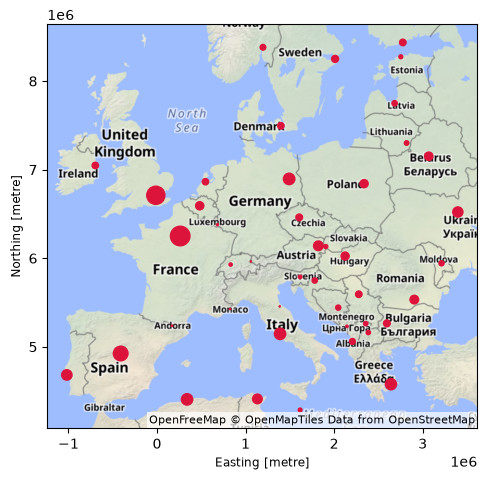

In [1]:
import geopandas
import matplotlib.pyplot as plt
import ml2drender.basemap as mlb

NE = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
places = geopandas.read_file(NE + "ne_50m_populated_places_simple.geojson")
capitals = places[places.featurecla == "Admin-0 capital"].cx[-12:32, 35:61]

ax = capitals.to_crs(3857).plot(figsize=(6, 5.25), color="crimson", markersize=capitals.pop_max / 5e4)
mlb.add_basemap(ax)

## In any CRS

Pass the CRS of the axes with `crs` (anything `pyproj.CRS.from_user_input` reads, such as a GeoDataFrame's `crs`). The style is drawn in that CRS directly, so labels stay upright and sharp. Here, the same capitals in the European LAEA projection (EPSG:3035) on CARTO's Positron.

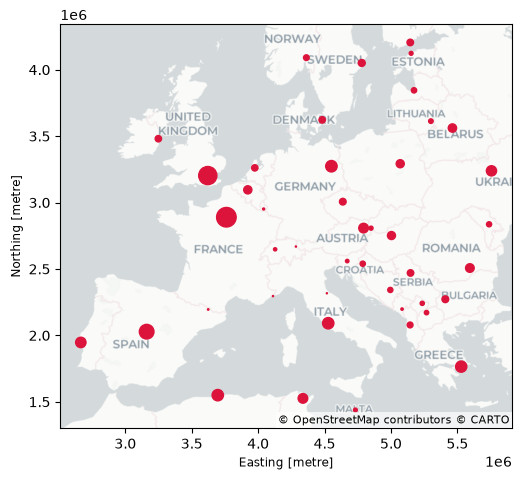

In [2]:
capitals_laea = capitals.to_crs(3035)
ax = capitals_laea.plot(figsize=(6, 5.25), color="crimson", markersize=capitals.pop_max / 5e4)
mlb.add_basemap(ax, crs=capitals_laea.crs, source="CartoDB.Positron")

In longitude and latitude (EPSG:4326), as GeoPandas plots them: here, the largest cities of Japan. GeoPandas stretches the latitudes (by 1 / cos of the middle latitude) to keep the shape of the map; the style is drawn in that stretched projection, so labels keep theirs.

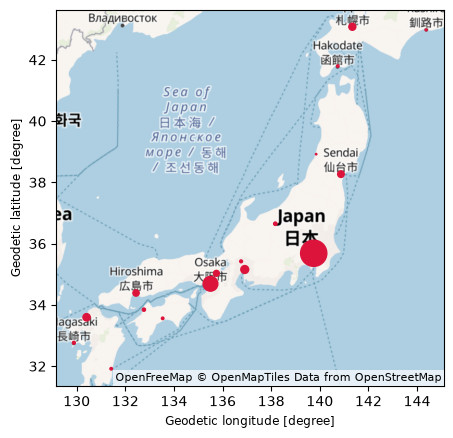

In [3]:
japan = places[places.adm0name == "Japan"].cx[128:146, 30:46]
ax = japan.plot(figsize=(5, 6), color="crimson", markersize=japan.pop_max / 1e5)
mlb.add_basemap(ax, crs=japan.crs, source="OpenFreeMap.Bright")

And the world's capitals in Equal Earth (EPSG:8857). Beyond the edge of the projection the image is transparent.

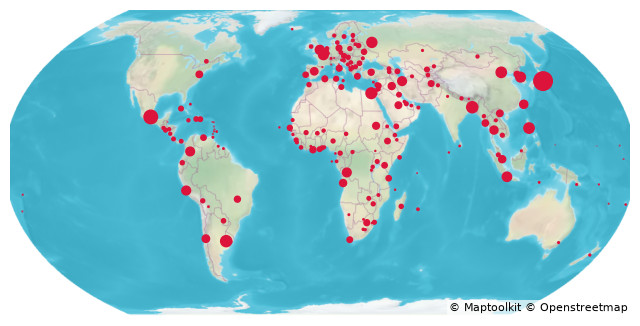

In [4]:
countries = geopandas.read_file(NE + "ne_110m_admin_0_countries.geojson")
world = places[places.featurecla == "Admin-0 capital"].to_crs(8857)

ax = world.plot(figsize=(8, 4.4), color="crimson", markersize=world.pop_max / 2e5)
ax.axis(countries.to_crs(8857).total_bounds[[0, 2, 1, 3]])
ax.set_axis_off()
mlb.add_basemap(ax, crs=world.crs, source="Maptoolkit.Summer")

### Compared with contextily

contextily downloads raster tiles in Web Mercator and warps them to the CRS of the axes, which turns and blurs their labels; `mlb` draws the style in that CRS. The defaults of each, on the capitals in EPSG:3035:

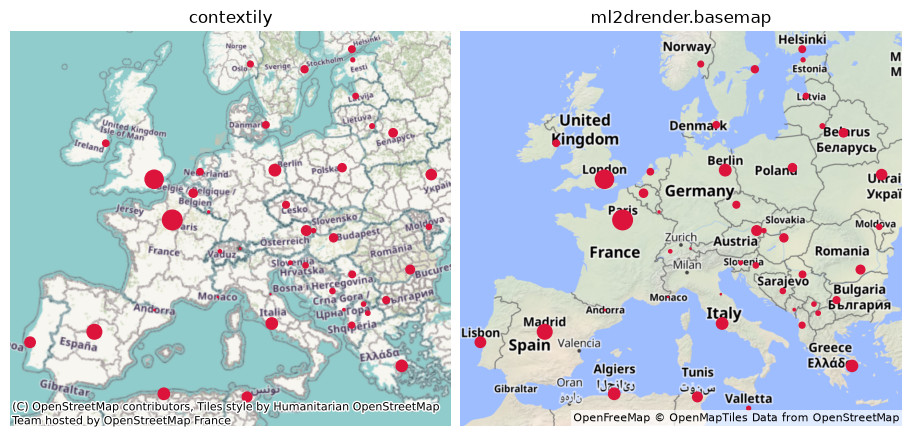

In [5]:
import contextily as cx

fig, axs = plt.subplots(1, 2, figsize=(9, 4.4), layout="constrained")
for ax, title in zip(axs, ["contextily", "ml2drender.basemap"], strict=True):
    capitals_laea.plot(ax=ax, color="crimson", markersize=capitals.pop_max / 5e4)
    ax.set_axis_off()
    ax.set_title(title)
cx.add_basemap(axs[0], crs=capitals_laea.crs)
mlb.add_basemap(axs[1], crs=capitals_laea.crs)

## Named styles

`source` is a MapLibre style: a name of `mlb.STYLES`, the URL of a style JSON, a style `dict` or a local `.json` file. The named ones load without an API key; check the terms of each service before heavy use.

In [6]:
print(", ".join(mlb.STYLES))

OpenFreeMap.Liberty, OpenFreeMap.Bright, OpenFreeMap.Positron, OpenFreeMap.Dark, OpenFreeMap.Fiord, VersaTiles.Colorful, VersaTiles.ColorfulDark, VersaTiles.ColorfulTerrain, VersaTiles.ColorfulDarkTerrain, VersaTiles.Natural, VersaTiles.NaturalDark, VersaTiles.NaturalTerrain, VersaTiles.NaturalDarkTerrain, VersaTiles.Muted, VersaTiles.MutedDark, VersaTiles.MutedTerrain, VersaTiles.MutedDarkTerrain, VersaTiles.Gray, VersaTiles.GrayDark, VersaTiles.GrayTerrain, VersaTiles.GrayDarkTerrain, VersaTiles.Toner, VersaTiles.TonerDark, VersaTiles.TonerTerrain, VersaTiles.TonerDarkTerrain, CartoDB.Positron, CartoDB.DarkMatter, CartoDB.Voyager, CartoDB.PositronNoLabels, CartoDB.DarkMatterNoLabels, CartoDB.VoyagerNoLabels, Maptoolkit.Summer, Maptoolkit.Winter, Maptoolkit.Street, Maptoolkit.Light, Maptoolkit.Dark, Maptoolkit.Cycling, Maptoolkit.Hiking, OpenHistoricalMap.Historical, OpenHistoricalMap.JapaneseScroll, OpenHistoricalMap.Woodblock, OpenHistoricalMap.Railway, MapLibre.Demotiles, BasemapDE

A few of them, by use, each with the default `zoom="auto"`. First, two helpers: the axes limits of a square around a point, and a grid of maps, one per style. Their axes are square (`ax.set_aspect("equal")`), as the extents are: axes of another shape would stretch the maps, labels too.

In [7]:
def around(lon, lat, half_width):
    """Axes limits of a square around (lon, lat), half_width Web Mercator meters to each side."""
    x, y = geopandas.GeoSeries.from_xy([lon], [lat], crs=4326).to_crs(3857).iloc[0].coords[0]
    return x - half_width, x + half_width, y - half_width, y + half_width


def gallery(maps, columns=3):
    """A grid of maps: maps is a dict of the name of a style to the axes limits to draw it in."""
    rows = -(-len(maps) // columns)
    width = 9.6 / columns
    axs = plt.subplots(rows, columns, figsize=(9.6, rows * (width + 0.3)), layout="constrained")[1].ravel()
    for ax in axs[len(maps) :]:
        ax.remove()
    for ax, (name, extent) in zip(axs[: len(maps)], maps.items(), strict=True):
        ax.axis(extent)
        ax.set_aspect("equal")
        ax.set_axis_off()
        ax.set_title(name, fontsize=9)
        mlb.add_basemap(ax, source=name)

### Street maps

General-purpose maps, here around Tokyo Station. OpenFreeMap and Maptoolkit label places in the local language and in Latin script, CARTO in Latin script only, VersaTiles in the local language only.

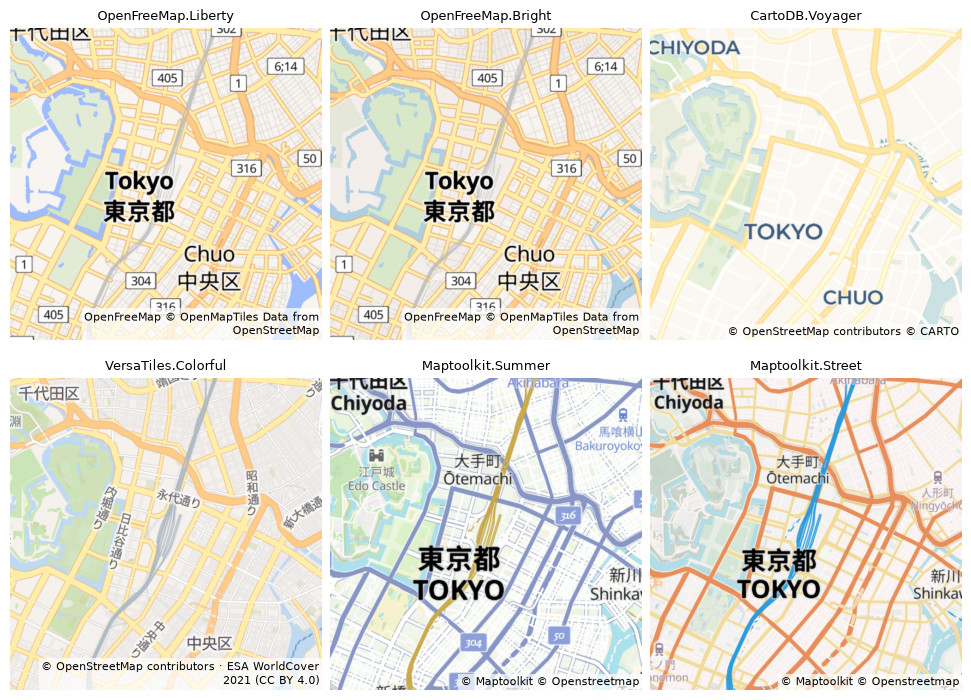

In [8]:
tokyo = around(139.767, 35.681, 2000)
names = ["OpenFreeMap.Liberty", "OpenFreeMap.Bright", "CartoDB.Voyager",
         "VersaTiles.Colorful", "Maptoolkit.Summer", "Maptoolkit.Street"]  # fmt: skip
gallery(dict.fromkeys(names, tokyo))

### Light and dark, for data on top

Quiet maps that leave the colours to your data, here in Midtown Manhattan.

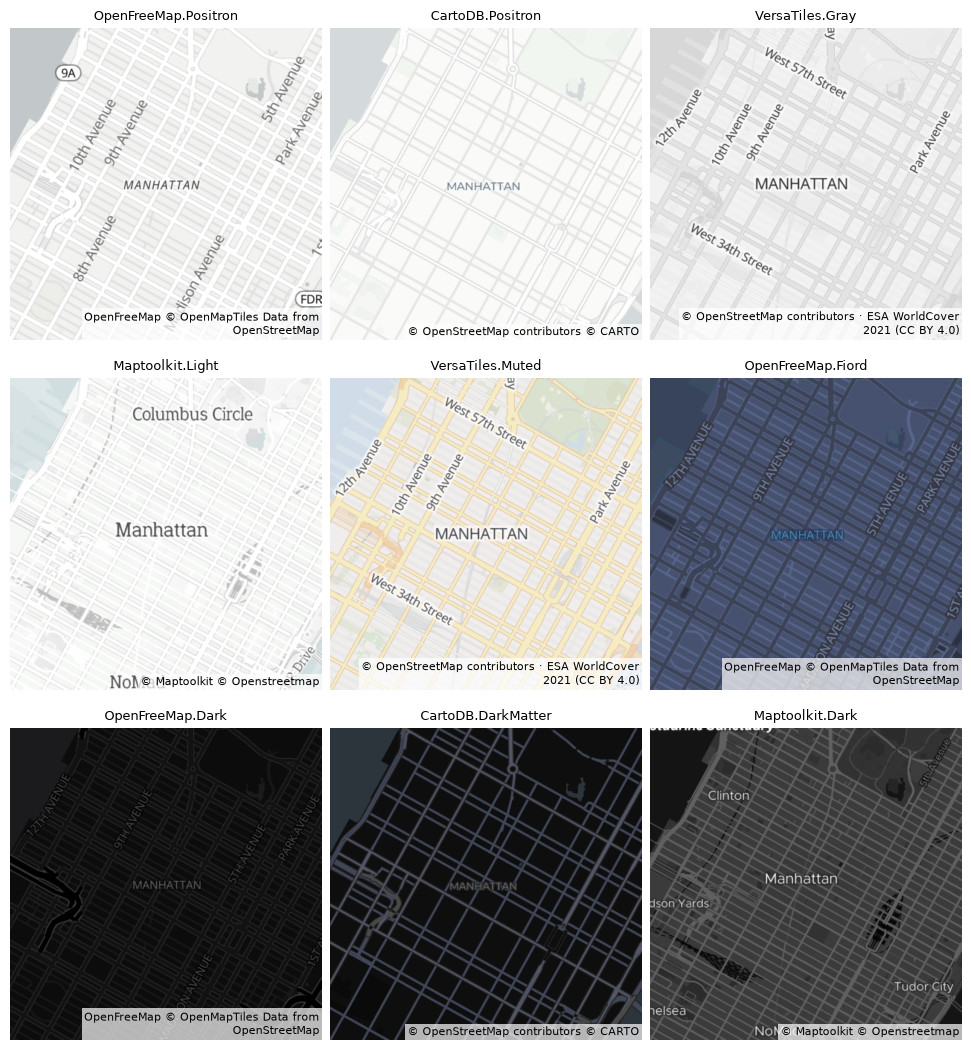

In [9]:
manhattan = around(-73.985, 40.758, 2000)
names = ["OpenFreeMap.Positron", "CartoDB.Positron", "VersaTiles.Gray",
         "Maptoolkit.Light", "VersaTiles.Muted", "OpenFreeMap.Fiord",
         "OpenFreeMap.Dark", "CartoDB.DarkMatter", "Maptoolkit.Dark"]  # fmt: skip
gallery(dict.fromkeys(names, manhattan))

### Outdoors and terrain

Maps for hiking, cycling and skiing, maps over a hillshade (the `...Terrain` styles of VersaTiles) and the relief of Mapterhorn's elevation data, here on Mount Fuji.

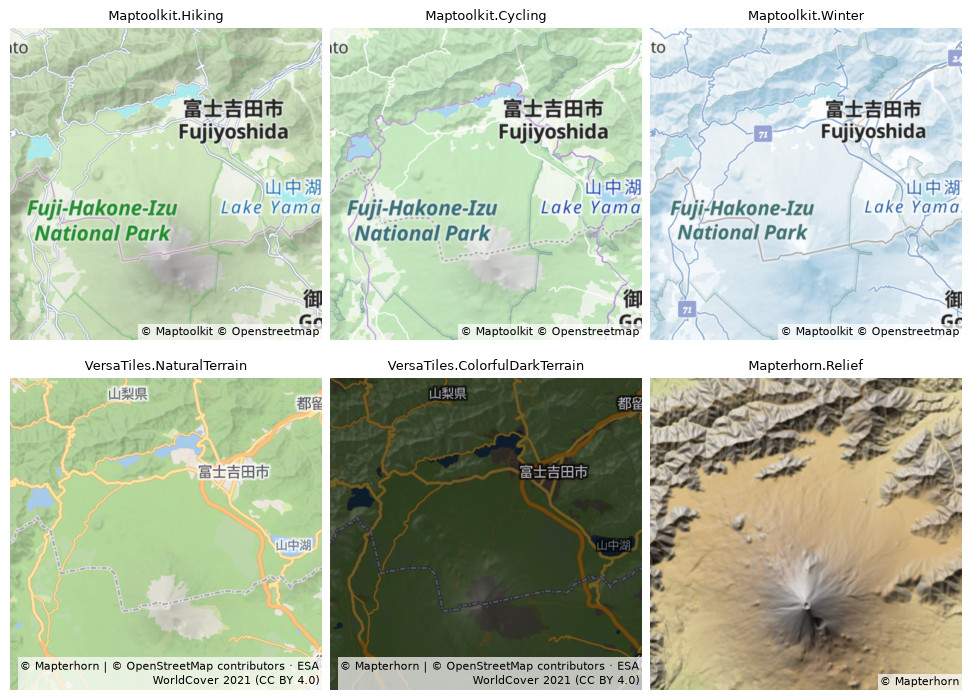

In [10]:
fuji = around(138.73, 35.43, 20000)
names = ["Maptoolkit.Hiking", "Maptoolkit.Cycling", "Maptoolkit.Winter",
         "VersaTiles.NaturalTerrain", "VersaTiles.ColorfulDarkTerrain", "Mapterhorn.Relief"]  # fmt: skip
gallery(dict.fromkeys(names, fuji))

### National mapping agencies

The maps of national agencies cover their country: Japan's GSI in Shinjuku and Osaka, Germany's basemap.de in Berlin and the Harz, swisstopo in Zürich and Zermatt, France's IGN in Paris and the Netherlands' PDOK in Amsterdam and Rotterdam.

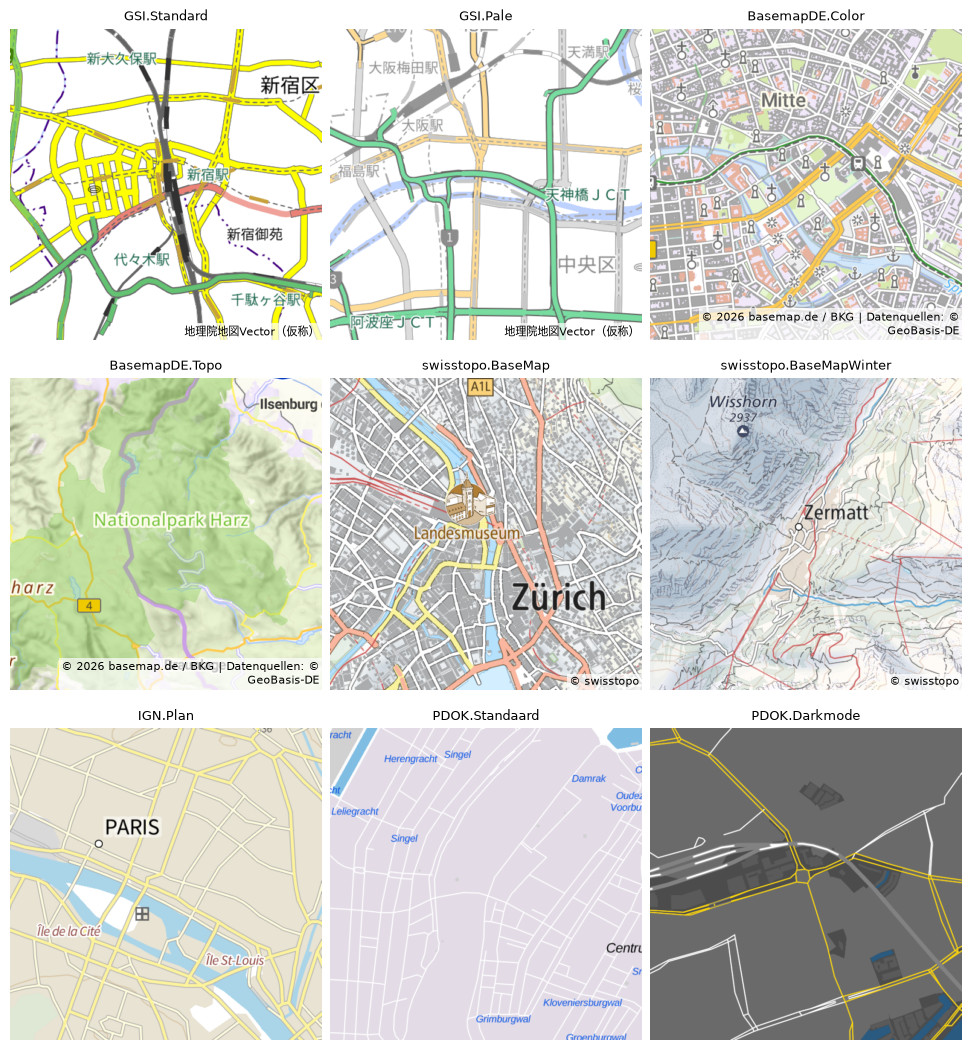

In [11]:
national = {
    "GSI.Standard": around(139.7, 35.69, 2000),
    "GSI.Pale": around(135.502, 34.694, 2000),
    "BasemapDE.Color": around(13.405, 52.52, 2000),
    "BasemapDE.Topo": around(10.615, 51.8, 15000),
    "swisstopo.BaseMap": around(8.542, 47.377, 2000),
    "swisstopo.BaseMapWinter": around(7.749, 46.021, 4000),
    "IGN.Plan": around(2.352, 48.857, 2000),
    "PDOK.Standaard": around(4.893, 52.373, 800),
    "PDOK.Darkmode": around(4.478, 51.924, 1500),
}
gallery(national)

### Imagery

Satellite and aerial imagery: VersaTiles' on the Palm Jumeirah in Dubai, Sentinel-2 by EOX of 2024 and of 2016 on Egypt's New Administrative Capital, built in between, and national orthophotos: USGS on the Grand Canyon, GSI on Himeji Castle, PDOK on the star fort of Bourtange, IGN on Mont-Saint-Michel and swisstopo (with its labels) on the Matterhorn.

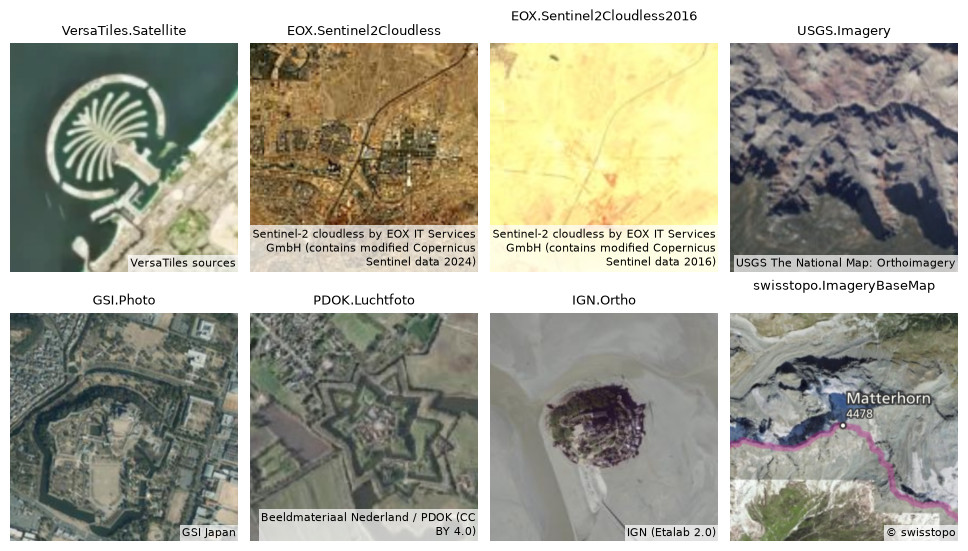

In [12]:
imagery = {
    "VersaTiles.Satellite": around(55.139, 25.112, 5000),
    "EOX.Sentinel2Cloudless": around(31.72, 30.02, 10000),
    "EOX.Sentinel2Cloudless2016": around(31.72, 30.02, 10000),
    "USGS.Imagery": around(-112.11, 36.08, 6000),
    "GSI.Photo": around(134.694, 34.839, 500),
    "PDOK.Luchtfoto": around(7.1914, 53.0067, 700),
    "IGN.Ortho": around(-1.511, 48.636, 500),
    "swisstopo.ImageryBaseMap": around(7.659, 45.976, 5000),
}
gallery(imagery, columns=4)

### Historical maps

[OpenHistoricalMap](https://www.openhistoricalmap.org/)'s styles draw its map as of today, as its website does: Japan as a scroll, Europe as a woodblock print, Tokyo and the railways of London.

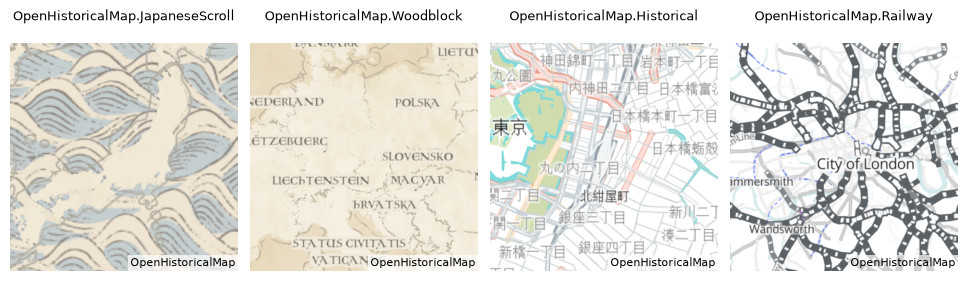

In [13]:
historical = {
    "OpenHistoricalMap.JapaneseScroll": around(137.5, 36.5, 900_000),
    "OpenHistoricalMap.Woodblock": around(14, 49, 1_300_000),
    "OpenHistoricalMap.Historical": around(139.767, 35.681, 2000),
    "OpenHistoricalMap.Railway": around(-0.12, 51.51, 15000),
}
gallery(historical, columns=4)

## Labels

`labels=True` (the default) draws the whole style, `labels=False` drops its labels and icons (its symbol layers), and `labels="only"` draws only them, on a transparent background (grey here, dark for a dark style). A city, a region and a country:

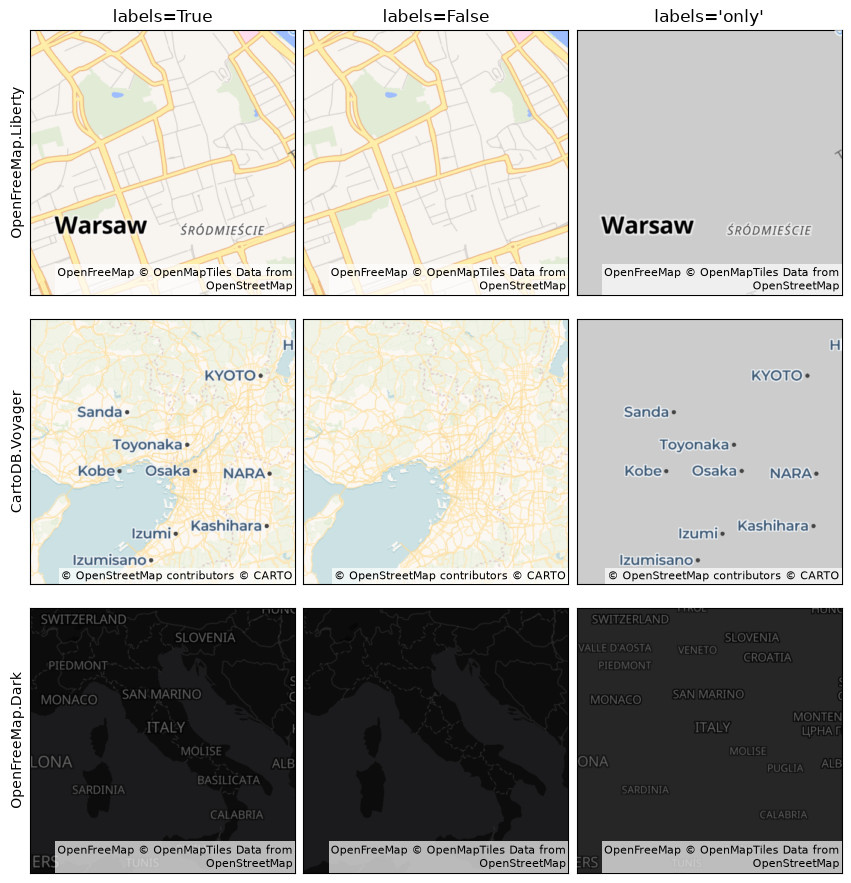

In [14]:
warsaw = around(21.013, 52.237, 1500)
examples = {
    "OpenFreeMap.Liberty": (warsaw, "0.8"),
    "CartoDB.Voyager": (around(135.4, 34.75, 60000), "0.8"),  # Kansai: Osaka, Kobe and Kyoto
    "OpenFreeMap.Dark": (around(12.5, 42.1, 800000), "0.15"),  # Italy
}
choices = [True, False, "only"]
fig, axs = plt.subplots(3, 3, figsize=(8.4, 8.8), layout="constrained")
for ax, labels in zip(axs[0], choices, strict=True):
    ax.set_title(f"labels={labels!r}")
for row, (name, (extent, background)) in zip(axs, examples.items(), strict=True):
    row[0].set_ylabel(name)
    for ax, labels in zip(row, choices, strict=True):
        ax.axis(extent)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_facecolor(background)
        mlb.add_basemap(ax, source=name, labels=labels)

Together they put your data between the map and its labels: here, a choropleth of GDP per capita. `labels="only"` goes above the data (`zorder` 9) unless `zorder` is given.

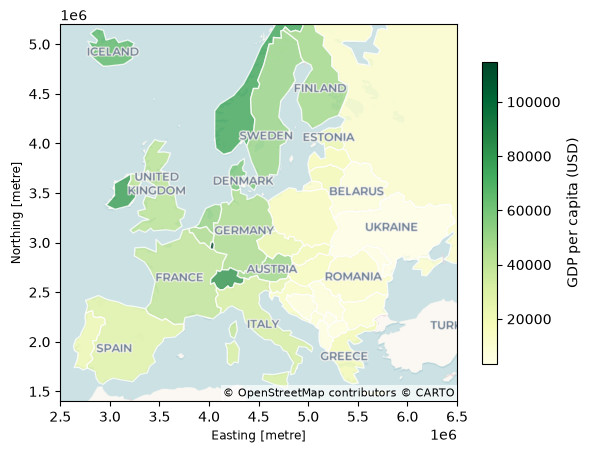

In [15]:
europe = countries[countries.CONTINENT == "Europe"].to_crs(3035).assign(gdp=lambda df: df.GDP_MD / df.POP_EST * 1e6)

legend = {"label": "GDP per capita (USD)", "shrink": 0.7}
ax = europe.plot("gdp", figsize=(6.4, 5.6), cmap="YlGn", alpha=0.8, edgecolor="white", legend=True, legend_kwds=legend)
ax.axis((2.5e6, 6.5e6, 1.4e6, 5.2e6))
mlb.add_basemap(ax, crs=europe.crs, source="CartoDB.Voyager", labels=False)
mlb.add_basemap(ax, crs=europe.crs, source="CartoDB.Voyager", labels="only")

## Level of detail and resolution

`zoom="auto"` (the default) draws the style at its size on a web page, so labels keep their size on paper. A number is contextily's zoom of 256-pixel tiles of the same scale, and `zoom_adjust` adds to either; both may be fractional.

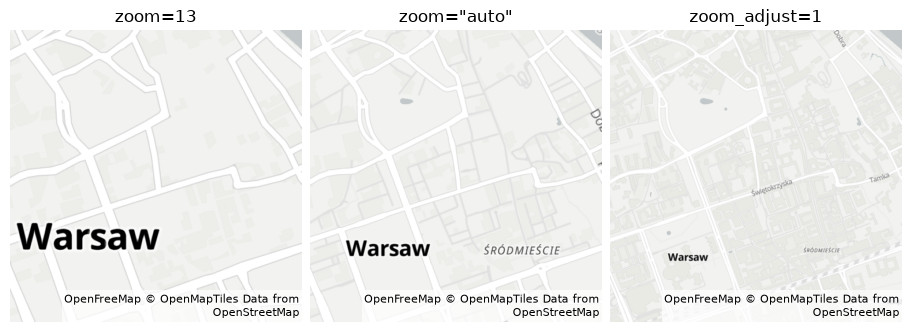

In [16]:
panels = {"zoom=13": {"zoom": 13}, 'zoom="auto"': {}, "zoom_adjust=1": {"zoom_adjust": 1}}
fig, axs = plt.subplots(1, 3, figsize=(9, 3.4), layout="constrained")
for ax, (title, options) in zip(axs, panels.items(), strict=True):
    ax.axis(warsaw)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title)
    mlb.add_basemap(ax, source="OpenFreeMap.Positron", **options)

By default the image has 192 pixels to the inch of the figure, or its dpi if higher: twice the resolution of a figure of the default dpi, sharp on HiDPI screens and in figures saved at twice their dpi. `pixel_ratio`, the image's pixels per CSS pixel, sets it instead (with `zoom="auto"` a CSS pixel is 1/96 inch, so the default is `max(2, dpi / 96)`): lower renders faster, higher is for print, such as `pixel_ratio=300 / 96` for `fig.savefig(..., dpi=300)`. Only the sharpness changes, not the map. Here, the Lake in Central Park at `pixel_ratio=1`, the default and `pixel_ratio=4`, and below them the framed detail of each image, enlarged to show its pixels.

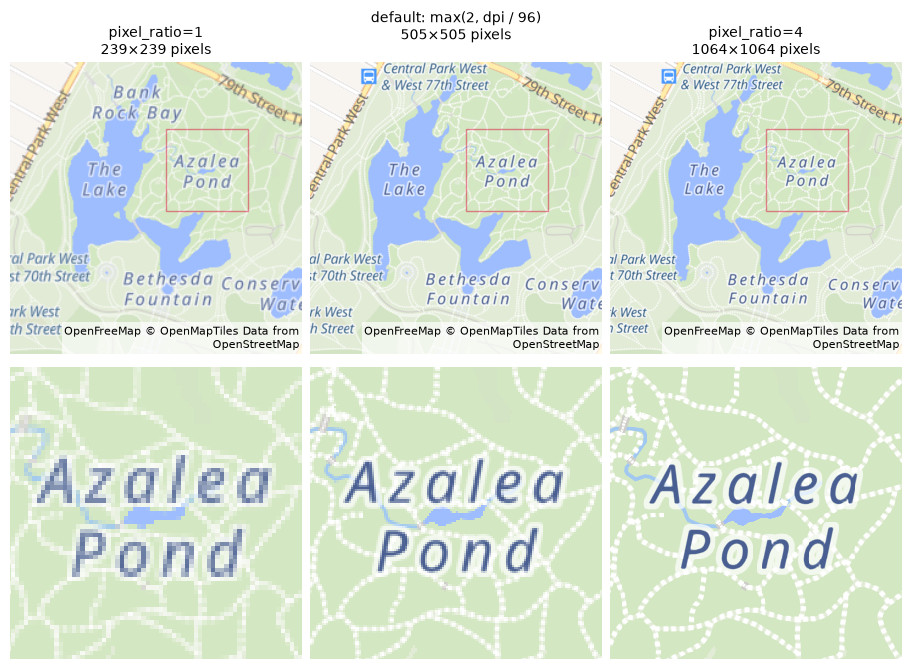

In [17]:
lake = around(-73.9712, 40.7762, 500)
x, y = (lake[0] + lake[1]) / 2, (lake[2] + lake[3]) / 2
detail = (x + 35, x + 315, y - 10, y + 270)  # Azalea Pond
fig, axs = plt.subplots(2, 3, figsize=(9, 6.6), layout="constrained")
for (ax, enlarged), ratio in zip(axs.T, [1, None, 4], strict=True):
    ax.axis(lake)
    ax.set_aspect("equal")
    ax.set_axis_off()
    name = "default: max(2, dpi / 96)" if ratio is None else f"pixel_ratio={ratio}"
    ax.set_title(f"{name}\n", fontsize=10)  # the size of the image goes on the second line
    mlb.add_basemap(ax, source="OpenFreeMap.Liberty", pixel_ratio=ratio)
    image = ax.images[0].get_array()
    height, width = image.shape[:2]
    ax.set_title(f"{name}\n{width}×{height} pixels", fontsize=10)
    ax.indicate_inset((detail[0], detail[2], detail[1] - detail[0], detail[3] - detail[2]), edgecolor="crimson")
    enlarged.imshow(image, extent=lake, interpolation="nearest")
    enlarged.axis(detail)
    enlarged.set_axis_off()

## Basemaps over one another

Draw basemaps over one another: they share one attribution. `Mapterhorn.Hillshade` is transparent, to shade another basemap, and imagery takes the labels of a map on top (`labels="only"`), or the whole map made translucent with `alpha` (it goes to `imshow`, as other extra arguments do).

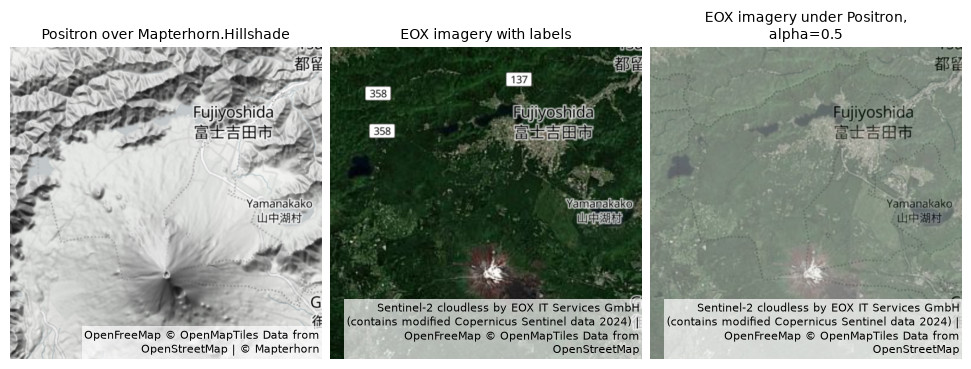

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(9.6, 3.6), layout="constrained")
titles = ["Positron over Mapterhorn.Hillshade", "EOX imagery with labels", "EOX imagery under Positron,\nalpha=0.5"]
for ax, title in zip(axs, titles, strict=True):
    ax.axis(fuji)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=10)
mlb.add_basemap(axs[0], source="OpenFreeMap.Positron", labels=False)
mlb.add_basemap(axs[0], source="Mapterhorn.Hillshade")
mlb.add_basemap(axs[0], source="OpenFreeMap.Positron", labels="only")
mlb.add_basemap(axs[1], source="EOX.Sentinel2Cloudless")
mlb.add_basemap(axs[1], source="OpenFreeMap.Liberty", labels="only")
mlb.add_basemap(axs[2], source="EOX.Sentinel2Cloudless")
mlb.add_basemap(axs[2], source="OpenFreeMap.Positron", alpha=0.5)

## Your own style

A style is a `dict`: change one, or write one from scratch. Here, Positron with blue water, and a layer added for green parks (in OpenMapTiles, city parks are `grass` in the `landcover` layer).

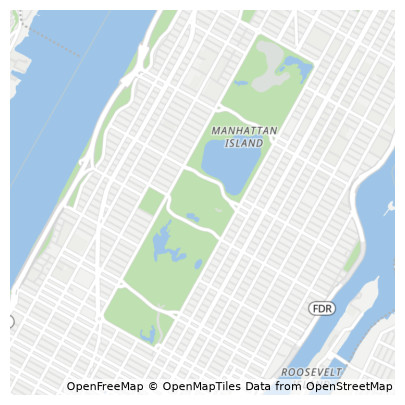

In [19]:
import httpx

style = httpx.get(mlb.STYLES["OpenFreeMap.Positron"]).json()
for layer in style["layers"]:
    if layer["id"] == "water":
        layer["paint"]["fill-color"] = "#9ec5e8"
grass = {
    "id": "grass",
    "type": "fill",
    "source": "openmaptiles",
    "source-layer": "landcover",
    "filter": ["==", ["get", "class"], "grass"],
    "paint": {"fill-color": "#bfe0b0"},
}
style["layers"].insert([layer["id"] for layer in style["layers"]].index("water"), grass)

fig, ax = plt.subplots(figsize=(5, 5))
ax.axis(around(-73.9665, 40.7812, 3200))
ax.set_aspect("equal")
ax.set_axis_off()
mlb.add_basemap(ax, source=style)

## More

- Attribution: the attributions of the style's sources are written in the corner, wrapped to the axes. Pass `attribution="..."` to replace them, `attribution=False` for none, or call `mlb.add_attribution(ax, text)`.
- Cache: downloads (tiles, sprites, glyphs) are cached on disk for the session; the style and its TileJSON are fetched each time, as they name the current tiles. Keep them across sessions with `mlb.set_cache_dir(path)`.
- Other sources: an `xyzservices` provider or its name, a URL of raster tiles or a raster file is not a MapLibre style. It is drawn by `contextily.add_basemap` (with a warning), so contextily needs to be installed.
- Rendering without matplotlib, other cameras and CRSs: see the [quick start](https://github.com/Kanahiro/ml2drender/blob/main/examples/python/quickstart.ipynb) and the [Python README](https://github.com/Kanahiro/ml2drender/tree/main/crates/python#readme).